# SeDriCa Perception · Q1 — The road disappears

| Part | Content |
|---|---|
| **Setup** | imports, constants, frame loader |
| **(a)** | hand-annotated frames: clear 002, shadow 008, missing 009 |
| **(b)** | baseline (white threshold 500), `predict_frame`, run on all 72 frames |
| **(c)** | evidence panel: difficult frame (missing 009) beside a clear frame (clear 002) |
| **(d)** | repair: baseline failure, brightness cue, revision (threshold 650), confidence |
| **(e)** | baseline vs revision error table, plot through the missing sequence, two failure frames, summary |

Origin is top-left, `u` grows right, `v` grows down. The lane centre is reported at the near row **`vn = 260`** and the far row **`vf = 170`**.
`lane_reference.csv` is read only after predicting, for scoring.

## Setup

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# PATHS
# --------------------------------------------------
# Folder that contains the three 24-frame sequences: clear/ shadow/ missing/
# (each frame is a 480 x 320 RGB png named 000.png ... 023.png).
# Change this if the starter-data folder lives somewhere else.
LANE_DIR = "SeDriCa_perception_starter_data/city/lane"

# --------------------------------------------------
# GEOMETRY CONSTANTS
# --------------------------------------------------
ROI_START_V = 80     # first image row of the road; rows above it are buildings
V_NEAR = 260         # row where the NEAR lane centre un is reported
V_FAR = 170          # row where the FAR  lane centre uf is reported

# --------------------------------------------------
# WHITE-PIXEL THRESHOLDS (on R+G+B, maximum 765)
# --------------------------------------------------
# A pixel counts as "white paint" when R+G+B >= threshold.
WHITE_THRESHOLD_BASELINE = 500   # baseline (part b): low threshold, accepts anything fairly bright
WHITE_THRESHOLD_REVISED = 650    # revised version (part d): sits between the seam and the paint
# NOTE: the detector functions below keep 650 as their default argument;
# the baseline therefore always passes WHITE_THRESHOLD_BASELINE explicitly.

In [2]:
def load_frame(sequence, frame_idx):
    """Load one frame of a lane sequence as an RGB image.

    sequence  : "clear", "shadow" or "missing"
    frame_idx : 0 ... 23
    """
    path = f"{LANE_DIR}/{sequence}/{frame_idx:03d}.png"

    # OpenCV reads images as BGR (and returns None if the path is wrong)
    image_bgr = cv.imread(path)
    if image_bgr is None:
        raise FileNotFoundError(f"Could not read {path} - check LANE_DIR")

    # Matplotlib (and the rest of this notebook) expects RGB
    return cv.cvtColor(image_bgr, cv.COLOR_BGR2RGB)

## Part (a) — Look before coding: hand-annotated frames

One frame per sequence, annotated by hand: **clear 002**, **shadow 008**, **missing 009**.
Blue lines = the two measurement rows (`vf = 170`, `vn = 260`), red = path to follow (lane centre), green = boundaries (dashed = where a hidden boundary must continue), orange = bright seam. These are a hypothesis, never fed to the detector.

**clear 002**

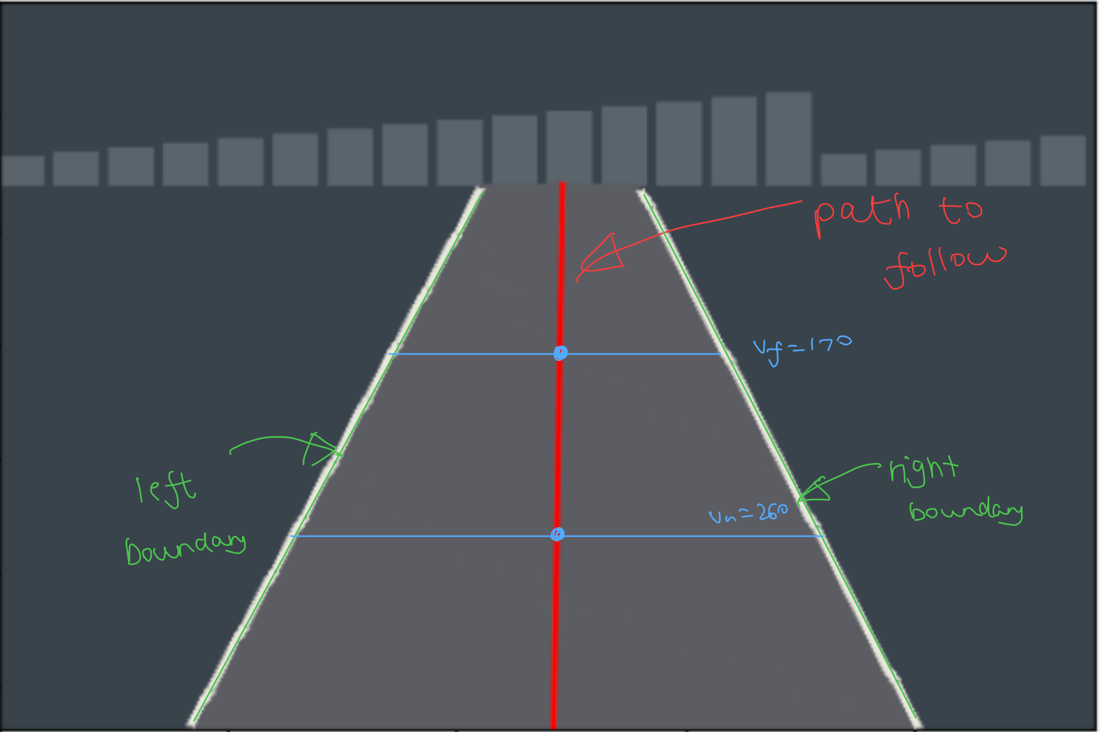

**shadow 008**

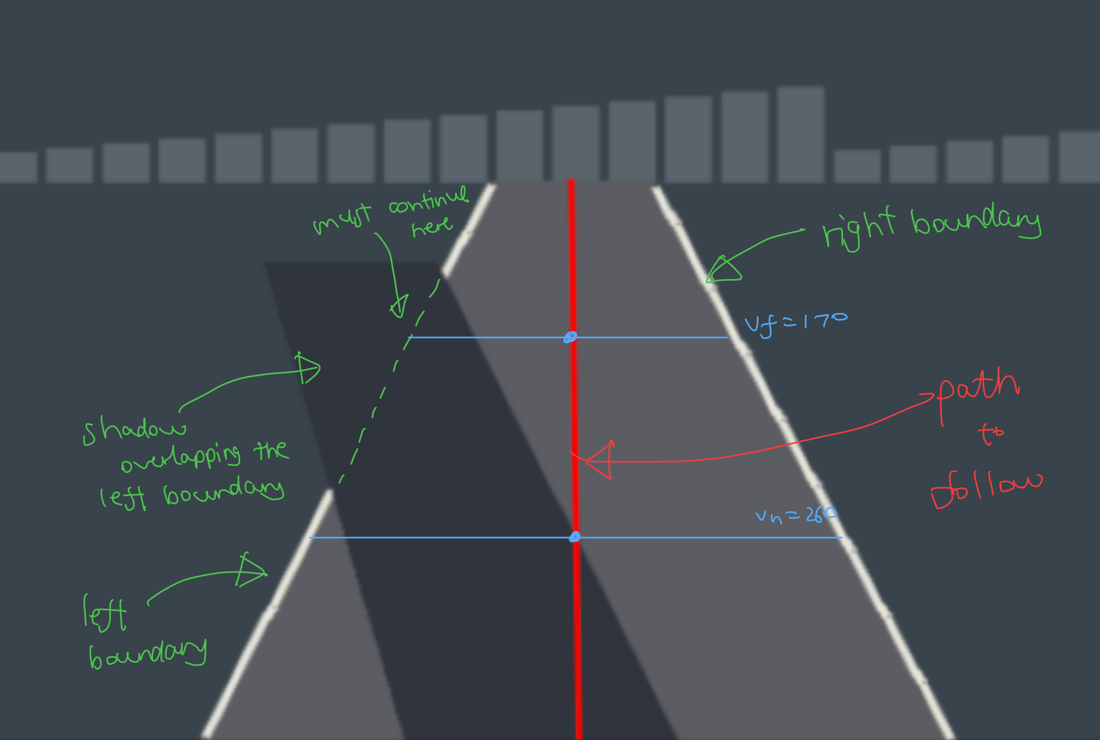

**missing 009**

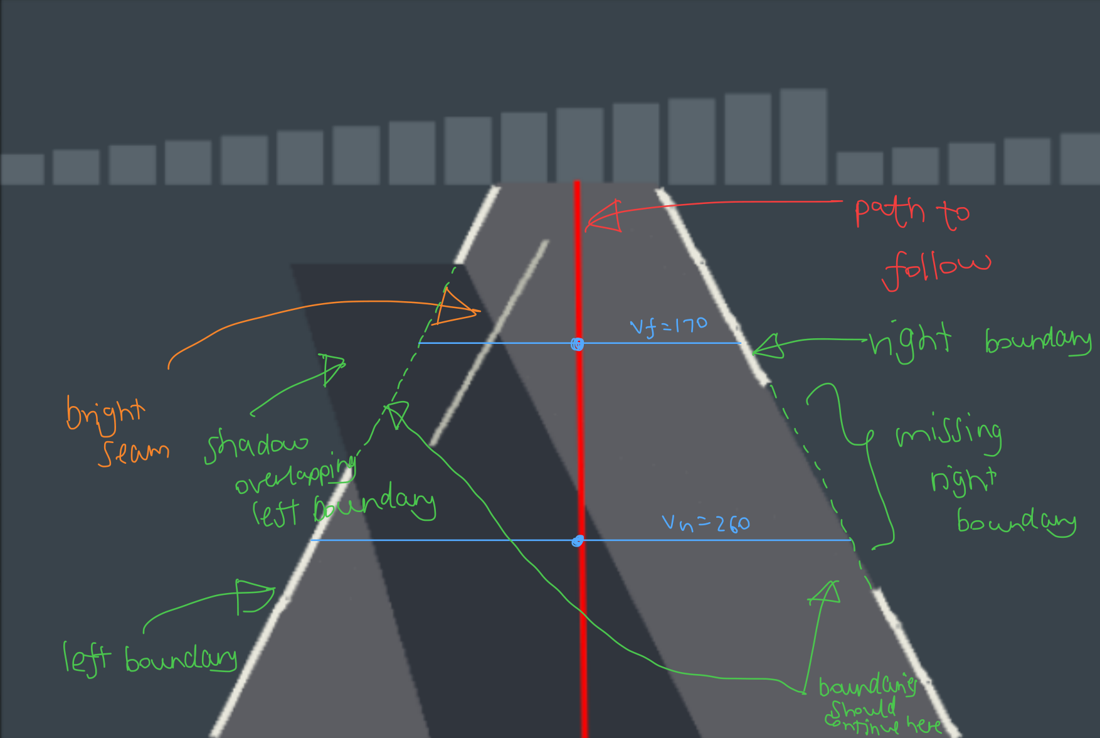

### What could fool a white-pixel threshold

Brightness = `R+G+B`: paint ≈ 686, lit road ≈ 282, background / shadow ≈ 160–200, seam ≈ 542.

* **Shadow** (shadow 008, missing 009): hides the left paint at the far row, so that edge must be continued from the visible part.
* **Bright seam** (missing 009): looks like a lane edge and sits where the true left edge is hidden. Any threshold below about 560 accepts it.
* **Missing paint** (missing 009): a gap in the right line, which must be continued.

## Part (b) — Baseline: one frame in, `(un, uf)` out

* **Region:** rows `v >= 80`.
* **Thresholds:** white = `R+G+B >= 500`; shadow = `R+G+B < 190`.
* **Method:** left edge = left-most white pixel in `u < 240`, right edge = right-most in `u >= 240`; one straight line per side; centre = midpoint of the two lines at `vn = 260` and `vf = 170`.
* **Assumptions:** edges are straight lines; anything with `R+G+B >= 500` is paint.
* **Unknown:** fewer than 2 edge points on a side gives `None`.

### Workflow of the baseline (what happens to one frame)

```
 frame (480 x 320 RGB)
        |
        v
 [1] keep only the road region: rows v >= 80                         (ROI_START_V)
        |
        v
 [2] for every ROI row v, find the white paint on each side          b.1  get_white_boundaries
        |     white pixel  =  R+G+B >= 500   (baseline threshold)
        |     left edge    =  left-most white pixel in the left half   (u < 240)
        |     right edge   =  right-most white pixel in the right half
        |     no white pixel on a side  ->  that row gives no point on that side
        v
 [3] collect the edge points of all rows -> left points, right points   b.3  collect_boundary_points
        |
        v
 [4] fit one straight line per side:  u = slope * v + intercept         b.4  fit_boundary
        |     fewer than 2 points  ->  no line  ->  unknown (None)
        v
 [5] read both lines at the two measurement rows                        b.5  boundary_x
        |     near row  vn = 260          far row  vf = 170
        |     (where the paint is hidden, the fitted line fills the gap in)
        v
 [6] lane centre = midpoint of the left and the right line              b.2  calculate_centre
        |
        v
 output:  (un, uf)  =  lane-centre u at vn and at vf, or None           b.9  predict_frame
```

**Side branch:** `get_dark_mask` (b.6) and `is_in_shadow` (b.8) flag points in shadow (used in part c); `get_road_mask` (b.7) is for display only.

**b.10** runs this on all 72 frames, with no labels.

### Detection pipeline (b.1 – b.8)

The paint is the brightest thing in the frame (`R+G+B` ≈ 686 vs ≈ 282 for the road), so we threshold it, fit a line per edge and read the centre off the lines.

### b.1 · `get_white_boundaries` — find the left / right white pixel in one row

In [3]:
def get_white_boundaries(image_rgb, v, white_threshold=650):
    """Return (left_x, right_x) = u-position of the outermost white pixel on each side of row v.
    Either value is None when no white pixel is found on that side ("unknown").

    white_threshold : minimum R+G+B for a pixel to count as "white" (max possible is 765)
    """

    # Take the pixels of row v -> shape (width, 3)
    row = image_rgb[v]

    # uint8 would overflow when adding 3 channels (255+255+255), so convert to int
    row = row.astype(np.int32)

    # Brightness proxy: R + G + B for every pixel in the row
    brightness_sum = row.sum(axis=1)

    # The image is split into a left and a right half at this column
    centre_x = 240

    # -------------------------
    # LEFT boundary
    # -------------------------

    # Only look at the left half of the row
    left_half = brightness_sum[:centre_x]

    # Indices of all pixels bright enough to be "white"
    left_white_pixels = np.where(
        left_half >= white_threshold
    )[0]

    if len(left_white_pixels) == 0:
        # nothing white on the left -> unknown
        left_x = None
    else:
        # left boundary = FIRST (left-most) white pixel
        left_x = left_white_pixels[0]

    # -------------------------
    # RIGHT boundary
    # -------------------------

    # Only look at the right half of the row
    right_half = brightness_sum[centre_x:]

    # Indices (relative to centre_x) of all "white" pixels
    right_white_pixels = np.where(
        right_half >= white_threshold
    )[0]

    if len(right_white_pixels) == 0:
        # nothing white on the right -> unknown
        right_x = None
    else:
        # right boundary = LAST (right-most) white pixel,
        # shifted by centre_x to get back to full-image coordinates
        right_x = centre_x + right_white_pixels[-1]

    return left_x, right_x

### b.2 · `calculate_centre` — midpoint of the two boundaries

In [4]:
def calculate_centre(left_x, right_x):
    """Lane centre = midpoint of the left and right boundary.
    Returns None if either boundary is unknown."""

    # A centre needs both boundaries
    if left_x is None:
        return None

    if right_x is None:
        return None

    # Midpoint of the two boundary positions
    centre = (left_x + right_x) / 2

    return centre

### b.3 · `collect_boundary_points` — run the row scan over the whole ROI

In [5]:
def collect_boundary_points(image_rgb, white_threshold=650):
    """Scan every ROI row and gather the detected boundary pixels.

    Returns two arrays of (v, u) pairs: left_points and right_points.
    Rows where a side had no white pixel are simply skipped.
    """

    left_points = []
    right_points = []

    height = image_rgb.shape[0]

    # Only rows from the ROI downwards (buildings above are ignored)
    for v in range(ROI_START_V, height):

        # Boundaries (or None) on this row
        left_x, right_x = get_white_boundaries(
            image_rgb,
            v,
            white_threshold
        )

        # Keep only the rows where a boundary was actually found
        if left_x is not None:
            left_points.append((v, left_x))

        if right_x is not None:
            right_points.append((v, right_x))

    # Lists -> arrays so they can be sliced column-wise later
    left_points = np.array(left_points)
    right_points = np.array(right_points)

    return left_points, right_points

### b.4 · `fit_boundary` — straight-line fit through the detected points

In [6]:
def fit_boundary(points):
    """Least-squares line  u = slope * v + intercept  through (v, u) points.
    Returns (slope, intercept), or None if there are fewer than 2 points.

    Because it is a line, it can be evaluated on rows where the boundary was
    NOT seen (e.g. inside a shadow) -> this is the inter/extrapolation.
    """

    # A line needs at least two points
    if len(points) < 2:
        return None

    # Column 0 = v (row), column 1 = u (horizontal position)
    v = points[:, 0]
    u = points[:, 1]

    # Degree-1 polynomial fit: u = slope * v + intercept
    slope, intercept = np.polyfit(v, u, 1)

    return slope, intercept

### b.5 · `boundary_x` — read a fitted line at a given row

In [7]:
def boundary_x(line, v):
    """Horizontal position u of a fitted boundary line at row v (None if no line)."""

    if line is None:
        return None

    slope, intercept = line

    # Evaluate  u = slope * v + intercept
    u = slope * v + intercept

    return u

### b.6 · `get_dark_mask` — which pixels are in shadow

In [8]:
def get_dark_mask(image_rgb, dark_threshold=190):
    """Boolean mask, True where R+G+B < dark_threshold (shadow / very dark pixels)."""

    # int32 so the channel sum cannot overflow
    image_int = image_rgb.astype(np.int32)

    # R + G + B per pixel -> shape (height, width)
    brightness_sum = image_int.sum(axis=2)

    # Dark = low brightness sum
    dark_mask = brightness_sum < dark_threshold

    return dark_mask

### b.7 · `get_road_mask` — fill the area between the two fitted boundaries

In [9]:
def get_road_mask(image_rgb, left_line, right_line):
    """Boolean mask that is True between the left and right fitted boundary lines
    (ROI rows only). Rows where either line is missing stay False."""

    height, width, channels = image_rgb.shape

    # Start with an all-False mask
    road_mask = np.zeros(
        (height, width),
        dtype=bool
    )

    for v in range(ROI_START_V, height):

        # Boundary positions on this row from the fitted lines
        left_x = boundary_x(left_line, v)
        right_x = boundary_x(right_line, v)

        # Can't fill a row if a boundary is missing
        if left_x is None or right_x is None:
            continue

        # Pixel indices must be integers
        left_x = int(round(left_x))
        right_x = int(round(right_x))

        # Keep them inside the image
        left_x = np.clip(left_x, 0, width - 1)
        right_x = np.clip(right_x, 0, width - 1)

        # Make sure left <= right before slicing
        if left_x > right_x:
            left_x, right_x = right_x, left_x

        # Everything between the boundaries is road
        road_mask[
            v,
            left_x:right_x + 1
        ] = True

    return road_mask

### b.8 · `is_in_shadow` — is one point (u, v) inside the dark mask

In [10]:
def is_in_shadow(shadow_mask, u, v):
    """True if pixel (u, v) is dark (inside the shadow). False for u = None or outside the image."""

    # Unknown coordinate -> cannot be in shadow
    if u is None:
        return False

    # Mask is indexed by integer pixels
    u = int(round(u))
    v = int(round(v))

    height, width = shadow_mask.shape

    # Outside the image -> not in shadow
    if not (
        0 <= u < width and
        0 <= v < height
    ):
        return False

    # Note the index order: row (v) first, column (u) second
    return bool(shadow_mask[v, u])

### b.9 · `predict_frame` — frame in, (un, uf) out

Baseline: `white_threshold=500`. Revision (part d): 650.

In [11]:
def predict_frame(image_rgb, white_threshold=650):
    """Baseline lane-centre estimate for one frame.

    Returns (un, uf): lane-centre u at the near row (V_NEAR) and the far row (V_FAR).
    A value is None ("unknown") when a boundary line could not be fitted.
    Only the pixels of the frame are used - no reference labels.
    """

    # Detect boundary pixels, then fit one straight line per side
    left_points, right_points = collect_boundary_points(image_rgb, white_threshold)
    left_line = fit_boundary(left_points)
    right_line = fit_boundary(right_points)

    # Lane centre = midpoint of the two fitted lines, read at each measurement row
    un = calculate_centre(boundary_x(left_line, V_NEAR), boundary_x(right_line, V_NEAR))
    uf = calculate_centre(boundary_x(left_line, V_FAR), boundary_x(right_line, V_FAR))

    return un, uf

### b.10 · Run the baseline (threshold 500) on all 72 frames (predictions only, no labels)

In [12]:
# Run the BASELINE (white threshold 500) on every frame: 3 sequences x 24 frames = 72 predictions.
# No reference labels are read here - scoring happens in parts (d) and (e).
predictions = {}
for sequence in ("clear", "shadow", "missing"):
    for frame_idx in range(24):
        image_rgb = load_frame(sequence, frame_idx)
        predictions[(sequence, frame_idx)] = predict_frame(image_rgb, white_threshold=WHITE_THRESHOLD_BASELINE)

# How many coordinates came back "unknown" (None)?
unknown_near = sum(un is None for un, uf in predictions.values())
unknown_far = sum(uf is None for un, uf in predictions.values())
print(f"frames run: {len(predictions)}   unknown near: {unknown_near}   unknown far: {unknown_far}")

# A look at the three frames used in part (a)
for key in (("clear", 2), ("shadow", 8), ("missing", 9)):
    un, uf = predictions[key]
    print(f"{key[0]:8s} {key[1]:03d}  un = {un:.1f}   uf = {uf:.1f}")

frames run: 72   unknown near: 0   unknown far: 0
clear    002  un = 243.3   uf = 244.5
shadow   008  un = 249.8   uf = 249.0
missing  009  un = 252.9   uf = 256.5


## Part (c) — Evidence panel: difficult frame beside a clear frame

Baseline (threshold 500). Top row: clear 002. Bottom row: missing 009.

| Column | Stage |
|---|---|
| 1 | Original image |
| 2 | Road region `img[80:, :]` with the two measurement rows (crop indexing: original row = crop row + 80) |
| 3 | The cue: accepted white pixels (lime: `R+G+B >= 650`; magenta: accepted only because the threshold is 500), boundary points (original coordinates), fitted line if a point is in shadow |
| 4 | Proposed lane centre and path |

In [13]:
def plot_difficult_frame(sequence, frame_idx, white_threshold=650, axes_row=None, verbose=True):
    """Draw the 4 stages (see the table above) for one frame.

    axes_row : 4 matplotlib axes to draw into (so several frames can be compared in one figure).
               If None, a standalone 2x2 figure is created and shown.
    """

    # ---------------------------------------------
    # Run the pipeline on this frame
    # ---------------------------------------------
    image_rgb = load_frame(sequence, frame_idx)
    roi = image_rgb[ROI_START_V:, :, :]            # road region: buildings cut away
    brightness = image_rgb.astype(np.int32).sum(axis=2)

    left_points, right_points = collect_boundary_points(image_rgb, white_threshold)
    left_line = fit_boundary(left_points)
    right_line = fit_boundary(right_points)
    shadow_mask = get_dark_mask(image_rgb)

    # Boundary points and lane centres at the far and near rows
    # (original-image coordinates; None where a boundary is unknown)
    rows = {"far": V_FAR, "near": V_NEAR}
    boundary_pts = []      # list of (u, v, in_shadow)
    centre_pts = []        # list of (u, v)
    for name, v in rows.items():
        left_u = boundary_x(left_line, v)
        right_u = boundary_x(right_line, v)
        for u in (left_u, right_u):
            if u is not None:
                boundary_pts.append((u, v, is_in_shadow(shadow_mask, u, v)))
        centre_u = calculate_centre(left_u, right_u)
        if centre_u is not None:
            centre_pts.append((centre_u, v))

    # Does any of the measured boundary points sit inside the shadow?
    shadow_overlap = any(in_shadow for _, _, in_shadow in boundary_pts)

    # ---------------------------------------------
    # Figure
    # ---------------------------------------------
    standalone = axes_row is None
    if standalone:
        fig, axs = plt.subplots(2, 2, figsize=(13, 9))
        axes_row = axs.ravel()
    ax1, ax2, ax3, ax4 = axes_row

    # ---- Stage 1: the entire unedited image ----
    ax1.imshow(image_rgb)
    ax1.set_title(f"1. Original  ({sequence} {frame_idx:03d})")

    # ---- Stage 2: road region + the two dotted measurement rows ----
    ax2.imshow(roi)
    for name, v in rows.items():
        v_crop = v - ROI_START_V                   # row index inside the cropped image
        ax2.axhline(v_crop, color="white", linestyle=":", linewidth=1.5)
        ax2.text(5, v_crop - 4, f"{name}: crop row {v_crop}  (original v = {v})",
                 color="white", fontsize=9)
    ax2.set_title(f"2. Road region img[{ROI_START_V}:, :]  (crop indexing)")

    # ---- Stage 3: the cue (accepted white pixels), boundary points, continued boundary ----
    ax3.imshow(roi)

    # Every pixel the detector accepted as "white". Lime = clearly paint (>= 650).
    # Magenta = accepted only because the threshold is low (seam / soft paint edge).
    n_magenta = 0
    for pts in (left_points, right_points):
        if len(pts) == 0:
            continue
        v_pts = pts[:, 0].astype(int)
        u_pts = pts[:, 1].astype(int)
        is_paint = brightness[v_pts, u_pts] >= WHITE_THRESHOLD_REVISED
        n_magenta += int((~is_paint).sum())
        ax3.plot(u_pts[is_paint], v_pts[is_paint] - ROI_START_V, ".", color="lime", markersize=2)
        ax3.plot(u_pts[~is_paint], v_pts[~is_paint] - ROI_START_V, ".", color="magenta", markersize=2)

    # If a boundary point lies in shadow, show the fitted (inter/extrapolated) boundary
    if shadow_overlap:
        v_all = np.arange(ROI_START_V, image_rgb.shape[0])
        for line in (left_line, right_line):
            if line is not None:
                ax3.plot([boundary_x(line, v) for v in v_all],
                         v_all - ROI_START_V, "--", color="yellow", linewidth=1.2)

    # Mark the boundary points. Yellow marker = point lies in the shadow.
    # The label shows the ORIGINAL image coordinates (u, v), not the crop row.
    for u, v, in_shadow in boundary_pts:
        ax3.plot(u, v - ROI_START_V, "o",
                 color="yellow" if in_shadow else "cyan",
                 markeredgecolor="black", markersize=8)
        ax3.annotate(f"({u:.1f}, {v})", (u, v - ROI_START_V),
                     xytext=(-8 if u < 240 else 8, -8),
                     textcoords="offset points",
                     ha="right" if u < 240 else "left",
                     color="white", fontsize=9,
                     bbox=dict(facecolor="black", alpha=0.6, pad=1.5))
    ax3.legend(handles=[
        plt.Line2D([], [], marker=".", linestyle="", color="lime", label="accepted, R+G+B >= 650"),
        plt.Line2D([], [], marker=".", linestyle="", color="magenta", label="accepted only because threshold is low"),
        plt.Line2D([], [], linestyle="--", color="yellow", label="fitted boundary (shown if a point is in shadow)"),
        plt.Line2D([], [], marker="o", linestyle="", color="yellow", markeredgecolor="black", label="point inside shadow"),
        plt.Line2D([], [], marker="o", linestyle="", color="cyan", markeredgecolor="black", label="point on visible road"),
    ], loc="lower center", fontsize=6.5, framealpha=0.8)
    ax3.set_title(f"3. Cue: accepted white pixels (threshold {white_threshold})")

    # ---- Stage 4: lane-centre points joined by the red dotted path ----
    ax4.imshow(roi)
    if len(centre_pts) == 2:
        (u_far, v_far), (u_near, v_near) = centre_pts
        ax4.plot([u_far, u_near], [v_far - ROI_START_V, v_near - ROI_START_V],
                 color="red", linestyle=":", linewidth=2.5)
    for u, v in centre_pts:
        ax4.plot(u, v - ROI_START_V, "o", color="red",
                 markeredgecolor="white", markersize=8)
        ax4.annotate(f"({u:.1f}, {v})", (u, v - ROI_START_V),
                     xytext=(10, -4), textcoords="offset points",
                     color="white", fontsize=9,
                     bbox=dict(facecolor="black", alpha=0.6, pad=1.5))
    ax4.set_title("4. Proposed lane-centre points and path")

    for ax in axes_row:
        ax.set_xlabel("u (px)")
        ax.set_ylabel("v (px)")

    if standalone:
        plt.tight_layout()
        plt.show()

    # Numbers behind the picture
    if verbose:
        print(f"{sequence} {frame_idx:03d} (threshold {white_threshold}): "
              f"shadow overlap = {shadow_overlap}, pixels accepted only because the threshold is low = {n_magenta}")
        for u, v, in_shadow in boundary_pts:
            print(f"    boundary  v={v}: u={u:.1f}   in shadow: {in_shadow}")
        for u, v in centre_pts:
            print(f"    centre    v={v}: u={u:.1f}")

clear 002 (threshold 500): shadow overlap = False, pixels accepted only because the threshold is low = 0
    boundary  v=170: u=161.5   in shadow: False
    boundary  v=170: u=327.5   in shadow: False
    boundary  v=260: u=112.9   in shadow: False
    boundary  v=260: u=373.8   in shadow: False
    centre    v=170: u=244.5
    centre    v=260: u=243.3
missing 009 (threshold 500): shadow overlap = True, pixels accepted only because the threshold is low = 78
    boundary  v=170: u=180.4   in shadow: True
    boundary  v=170: u=332.6   in shadow: False
    boundary  v=260: u=124.8   in shadow: False
    boundary  v=260: u=381.1   in shadow: False
    centre    v=170: u=256.5
    centre    v=260: u=252.9


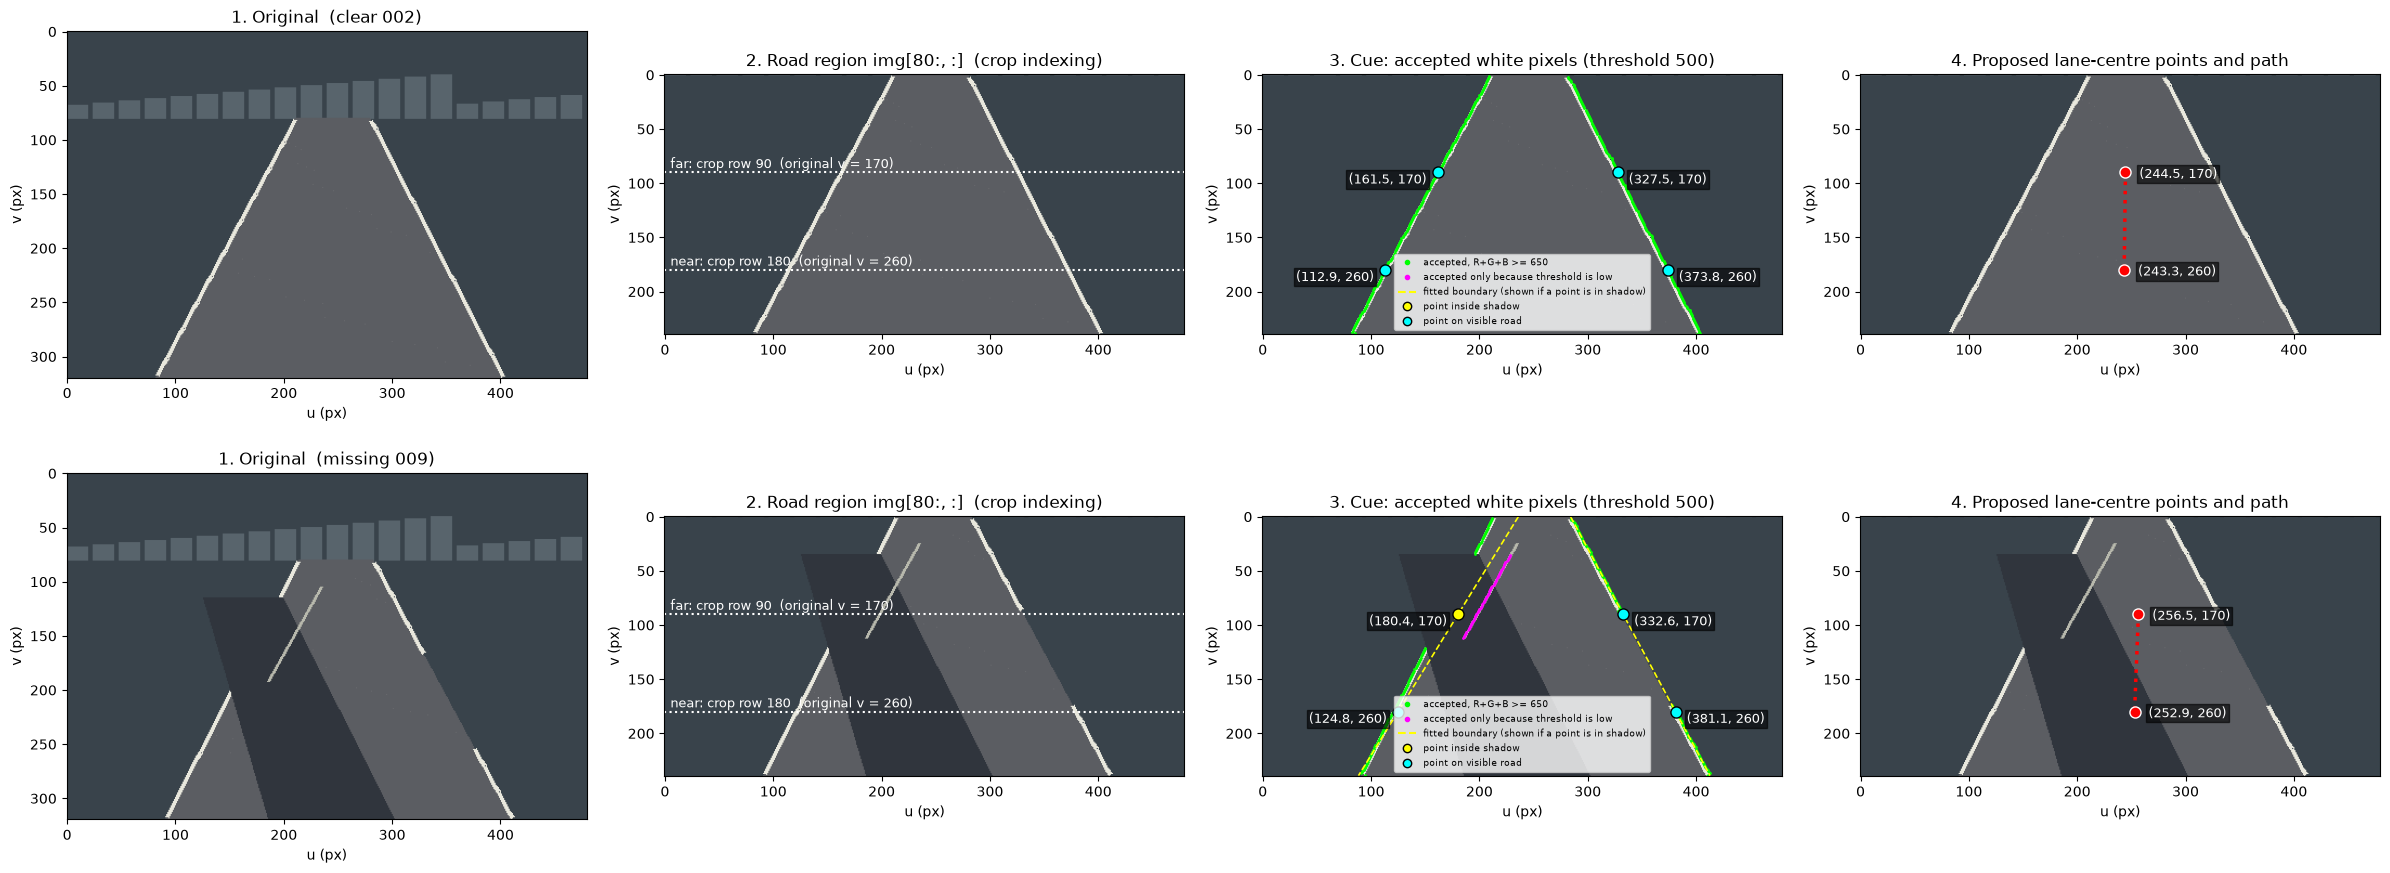

In [14]:
# Clear frame (top row) beside the difficult frame (bottom row), both with the BASELINE threshold
fig, axes = plt.subplots(2, 4, figsize=(24, 9))

plot_difficult_frame("clear", 2, WHITE_THRESHOLD_BASELINE, axes_row=axes[0])
plot_difficult_frame("missing", 9, WHITE_THRESHOLD_BASELINE, axes_row=axes[1])

plt.tight_layout()
plt.show()

### What persuades the method, and what misleads it

* **Persuades (lime):** the paint is the brightest thing (≈ 686 vs ≈ 282 for the road), so on the clear frame each edge is clean.
* **Misleads (magenta):** in missing 009 the left paint is hidden by the shadow, so the left-most pixel ≥ 500 is a **seam** pixel (≈ 542). The fit tilts and the far centre shifts right.
* **Missing right paint:** harmless, the fitted line continues it.
* **Colour space:** only `R+G+B` is used. It separates paint, road and background, but not paint from the seam at threshold 500.

## Part (d) — Repair a real failure

* **Failure (d.2):** at threshold 500 the seam is taken as a lane edge on missing frames 04–14 (far-row error up to 6.7 px).
* **Cue (d.3, d.4):** brightness. Seam ≈ 542 < paint ≈ 686, so a threshold between them rejects the seam.
* **Revision (d.5):** same pipeline with threshold **650**, plus a confidence per estimate.

Failure = unknown, or error > `FAIL_TOL_PX` (3 px). Reference is read only after predicting.

### d.1 · `evaluate_all` — run every frame, score afterwards, list the failures

In [15]:
import csv

# Evaluation labels: used ONLY to score finished predictions, never inside a detector
REFERENCE_CSV = "SeDriCa_perception_starter_data/city/lane_reference.csv"
FAIL_TOL_PX = 3.0      # a prediction further than this from the reference counts as a failure


def evaluate_all(white_threshold=650):
    """Run predict_frame on all 72 frames and compare with the reference AFTER predicting.

    Returns (results, failures). Each result is a dict with the sequence, frame,
    predictions, errors (None when unknown) and a failure flag.
    """

    # 1) Predictions first (no labels touched)
    predictions = {}
    for sequence in ("clear", "shadow", "missing"):
        for frame_idx in range(24):
            image_rgb = load_frame(sequence, frame_idx)
            predictions[(sequence, frame_idx)] = predict_frame(image_rgb, white_threshold)

    # 2) Only now read the reference and score
    with open(REFERENCE_CSV) as f:
        reference = {(r["sequence"], int(r["frame"])): r for r in csv.DictReader(f)}

    results = []
    for (sequence, frame_idx), (un, uf) in predictions.items():
        ref = reference[(sequence, frame_idx)]
        err_n = None if un is None else abs(un - float(ref["near_center_x_px"]))
        err_f = None if uf is None else abs(uf - float(ref["far_center_x_px"]))

        # Unknown or too far from the truth = failure
        failed = any(e is None or e > FAIL_TOL_PX for e in (err_n, err_f))
        results.append(dict(sequence=sequence, frame=frame_idx, un=un, uf=uf,
                            err_near=err_n, err_far=err_f, failed=failed))

    failures = [r for r in results if r["failed"]]
    return results, failures

### d.2 · The failure: baseline (white threshold 500) on all 72 frames

In [16]:
results, failures = evaluate_all(white_threshold=WHITE_THRESHOLD_BASELINE)

print(f"frames run: {len(results)}   failing: {len(failures)}   (tolerance {FAIL_TOL_PX} px)")
print(f"unknown near: {sum(r['un'] is None for r in results)}   unknown far: {sum(r['uf'] is None for r in results)}")

for seq in ("clear", "shadow", "missing"):
    errs_n = [r["err_near"] for r in results if r["sequence"] == seq and r["err_near"] is not None]
    errs_f = [r["err_far"] for r in results if r["sequence"] == seq and r["err_far"] is not None]
    print(f"{seq:8s} mean |error|  near: {np.mean(errs_n):.2f} px   far: {np.mean(errs_f):.2f} px")

for r in failures:
    print("FAIL", r["sequence"], r["frame"], "near err", r["err_near"], "far err", r["err_far"])

frames run: 72   failing: 11   (tolerance 3.0 px)
unknown near: 0   unknown far: 0
clear    mean |error|  near: 0.16 px   far: 0.17 px
shadow   mean |error|  near: 0.17 px   far: 0.17 px
missing  mean |error|  near: 1.04 px   far: 2.59 px
FAIL missing 4 near err 2.1836182503272994 far err 3.06342203472218
FAIL missing 5 near err 2.313939482102512 far err 3.7373552516719997
FAIL missing 6 near err 2.4193202902200994 far err 4.556435004673631
FAIL missing 7 near err 2.3865923929071187 far err 5.186192749979881
FAIL missing 8 near err 2.2563909013927628 far err 6.131007037263487
FAIL missing 9 near err 2.0673784005980735 far err 6.713849279205277
FAIL missing 10 near err 1.8350681920343561 far err 6.40861250209457
FAIL missing 11 near err 1.334228402517624 far err 5.685101277695679
FAIL missing 12 near err 0.7689930326361321 far err 4.84247328855065
FAIL missing 13 near err 0.33306127013932496 far err 3.8807442266336523
FAIL missing 14 near err 0.28565110116042547 far err 3.00760308496663

### d.3 · The cue: brightness separates the paint from the seam

Histogram of `R+G+B` over all ROI pixels of the `missing` frames (log scale). The seam and paint clusters are well separated.

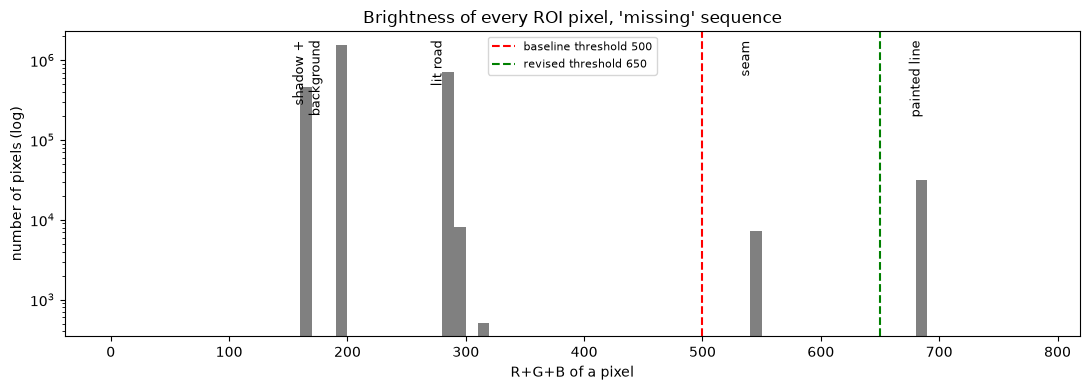

accepted at 650 (paint):                    n =  7835   R+G+B min 686  median 686  max 686
accepted only at 500 (the seam):            n =   728   R+G+B min 542  median 542  max 542


In [17]:
# R+G+B of every ROI pixel in the 24 "missing" frames
sums = np.concatenate([
    load_frame("missing", f)[ROI_START_V:].astype(np.int32).sum(axis=2).ravel()
    for f in range(24)
])

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(sums, bins=np.arange(0, 781, 10), color="gray")
ax.set_yscale("log")                      # the seam and paint clusters are tiny next to the road
ax.axvline(WHITE_THRESHOLD_BASELINE, color="red", linestyle="--", label="baseline threshold 500")
ax.axvline(WHITE_THRESHOLD_REVISED, color="green", linestyle="--", label="revised threshold 650")

# Cluster labels (positions read from the histogram)
for x, label in ((180, "shadow +\nbackground"), (282, "lit road"), (542, "seam"), (686, "painted line")):
    ax.text(x, 0.97, label, transform=ax.get_xaxis_transform(), rotation=90,
            va="top", ha="right", fontsize=9)
ax.set_xlabel("R+G+B of a pixel")
ax.set_ylabel("number of pixels (log)")
ax.set_title("Brightness of every ROI pixel, 'missing' sequence")
ax.legend(loc="upper center", fontsize=8)
plt.tight_layout()
plt.show()

# Pixels the detector accepted as edge pixels, split by which threshold lets them in
paint_sums, low_sums = [], []
for f in range(24):
    image_rgb = load_frame("missing", f)
    brightness = image_rgb.astype(np.int32).sum(axis=2)
    for pts in collect_boundary_points(image_rgb, WHITE_THRESHOLD_BASELINE):
        for v, u in pts:
            value = brightness[int(v), int(u)]
            (paint_sums if value >= WHITE_THRESHOLD_REVISED else low_sums).append(value)
print(f"accepted at 650 (paint):                    n = {len(paint_sums):5d}   R+G+B min {min(paint_sums)}  median {np.median(paint_sums):.0f}  max {max(paint_sums)}")
print(f"accepted only at 500 (the seam):            n = {len(low_sums):5d}   R+G+B min {min(low_sums)}  median {np.median(low_sums):.0f}  max {max(low_sums)}")

### d.4 · Threshold sweep

At 500 or below the seam gets in; at 700 or above the paint is rejected (all unknown). 650 sits between the seam and the paint.

In [18]:
print("white_threshold | failing frames | unknown values | worst error (px)")
for threshold in (750, 700, 680, 650, 600, 550, 500, 450, 400):
    _, fails = evaluate_all(threshold)
    unknown = sum(r["un"] is None for r in fails) + sum(r["uf"] is None for r in fails)
    worst = max([e for r in fails for e in (r["err_near"], r["err_far"]) if e is not None], default=0)
    print(f"{threshold:15d} | {len(fails):14d} | {unknown:14d} | {worst:.1f}")


white_threshold | failing frames | unknown values | worst error (px)
            750 |             72 |            144 | 0.0


            700 |             72 |            144 | 0.0


            680 |              0 |              0 | 0.0


            650 |              0 |              0 | 0.0
            600 |              0 |              0 | 0.0
            550 |              0 |              0 | 0.0


            500 |             11 |              0 | 6.7
            450 |             11 |              0 | 6.7
            400 |             11 |              0 | 6.7


### d.5 · Revision: threshold 650 and a confidence per estimate

Same detector with threshold 650 (justified by d.3 and d.4), current frame only. `conf_near` goes with `un`, `conf_far` with `uf`.

$$\text{confidence} = 1 - 0.5 \times (\text{fraction of the row's boundaries taken from the fitted line})$$

* On a row, each boundary is either *detected directly* (white pixel found on that row) or *taken from the fitted line* (shadow, paint gap).
* Both seen directly: **1.0**. One hidden: **0.75**. Both hidden: **0.5**. Unknown (`None`): **0**.

It ranks trust; it is not a calibrated probability.

In [19]:
def directly_detected(image_rgb, v, white_threshold=650):
    """For row v: was each boundary found as a white pixel ON THAT ROW?
    Returns (left_detected, right_detected). False means the boundary at this row
    can only come from the fitted line (inter/extrapolated)."""

    left_x, right_x = get_white_boundaries(image_rgb, v, white_threshold)

    return left_x is not None, right_x is not None

In [20]:
def confidence_at_row(image_rgb, v, estimate, white_threshold=650):
    """confidence = 1 - 0.5 * (fraction of this row's boundaries that come from the fitted line).

    estimate : the lane-centre u returned for this row (None = unknown -> confidence 0)
    """

    # No estimate -> nothing to trust
    if estimate is None:
        return 0.0

    left_detected, right_detected = directly_detected(image_rgb, v, white_threshold)

    # Number of boundaries (out of 2) that were NOT seen on this row
    n_from_fit = (not left_detected) + (not right_detected)
    fraction_from_fit = n_from_fit / 2

    return 1 - 0.5 * fraction_from_fit

In [21]:
def predict_with_confidence(image_rgb, white_threshold=650):
    """Baseline estimate plus confidence for both rows.
    Returns (un, uf, conf_near, conf_far). The estimates are exactly those of predict_frame."""

    un, uf = predict_frame(image_rgb, white_threshold)

    conf_near = confidence_at_row(image_rgb, V_NEAR, un, white_threshold)
    conf_far = confidence_at_row(image_rgb, V_FAR, uf, white_threshold)

    return un, uf, conf_near, conf_far

### d.6 · Run the revised version on all 72 frames

In [22]:
# Revised version (white threshold 650): estimates + confidence, no labels used here
revised_rows = []
for sequence in ("clear", "shadow", "missing"):
    for frame_idx in range(24):
        image_rgb = load_frame(sequence, frame_idx)
        un, uf, conf_near, conf_far = predict_with_confidence(image_rgb, WHITE_THRESHOLD_REVISED)
        revised_rows.append(dict(sequence=sequence, frame=frame_idx, un=un, uf=uf,
                                 conf_near=conf_near, conf_far=conf_far))

print("sequence | mean conf near | mean conf far")
for sequence in ("clear", "shadow", "missing"):
    rows = [r for r in revised_rows if r["sequence"] == sequence]
    print(f"{sequence:8s} | {np.mean([r['conf_near'] for r in rows]):14.3f} | {np.mean([r['conf_far'] for r in rows]):13.3f}")

print()
for level in (1.0, 0.75, 0.5, 0.0):
    count = sum(r[k] == level for r in revised_rows for k in ("conf_near", "conf_far"))
    print(f"confidence {level:4.2f}: {count} of {2 * len(revised_rows)} estimates")

# Does the repair fix the failures? (reference used only to score)
_, revised_failures = evaluate_all(white_threshold=WHITE_THRESHOLD_REVISED)
_, baseline_failures = evaluate_all(white_threshold=WHITE_THRESHOLD_BASELINE)
print()
print(f"failing frames (unknown or error > {FAIL_TOL_PX} px):  baseline = {len(baseline_failures)},  revised = {len(revised_failures)}")

sequence | mean conf near | mean conf far
clear    |          1.000 |         1.000
shadow   |          0.938 |         0.854
missing  |          0.948 |         0.656

confidence 1.00: 95 of 144 estimates
confidence 0.75: 40 of 144 estimates
confidence 0.50: 9 of 144 estimates
confidence 0.00: 0 of 144 estimates

failing frames (unknown or error > 3.0 px):  baseline = 11,  revised = 0


## Part (e) — Measure the change

MAE (px) over the frames that returned a coordinate, and the fraction unknown. Baseline = 500, revision = 650. Reference is read only after predicting (`evaluate_all`, d.1).

### e.1 · Baseline vs revision: MAE and unknown fraction

In [23]:
# Predictions first, scored afterwards (evaluate_all reads the reference only after predicting)
res_base, _ = evaluate_all(white_threshold=WHITE_THRESHOLD_BASELINE)
res_rev, _ = evaluate_all(white_threshold=WHITE_THRESHOLD_REVISED)

def mae_and_unknown(results, sequence, err_key):
    """MAE over the frames that returned a coordinate, and the fraction of frames that did not."""
    rows = [r for r in results if r["sequence"] == sequence]
    errors = [r[err_key] for r in rows if r[err_key] is not None]
    mae = np.mean(errors) if errors else float("nan")
    unknown_fraction = 1 - len(errors) / len(rows)
    return mae, unknown_fraction

print("                         |   BASELINE (500)    |   REVISION (650)")
print("sequence | row           |  MAE (px) | unknown |  MAE (px) | unknown")
for sequence in ("clear", "shadow", "missing"):
    for row_name, err_key in (("near (vn=260)", "err_near"), ("far  (vf=170)", "err_far")):
        mae_b, unk_b = mae_and_unknown(res_base, sequence, err_key)
        mae_r, unk_r = mae_and_unknown(res_rev, sequence, err_key)
        print(f"{sequence:8s} | {row_name} | {mae_b:9.3f} | {unk_b:6.1%}  | {mae_r:9.3f} | {unk_r:6.1%}")

                         |   BASELINE (500)    |   REVISION (650)
sequence | row           |  MAE (px) | unknown |  MAE (px) | unknown
clear    | near (vn=260) |     0.155 |   0.0%  |     0.155 |   0.0%
clear    | far  (vf=170) |     0.173 |   0.0%  |     0.173 |   0.0%
shadow   | near (vn=260) |     0.170 |   0.0%  |     0.239 |   0.0%
shadow   | far  (vf=170) |     0.171 |   0.0%  |     0.248 |   0.0%
missing  | near (vn=260) |     1.040 |   0.0%  |     0.176 |   0.0%
missing  | far  (vf=170) |     2.592 |   0.0%  |     0.176 |   0.0%


### e.2 · Estimated and reference `un` (and `uf`) through the missing-line sequence

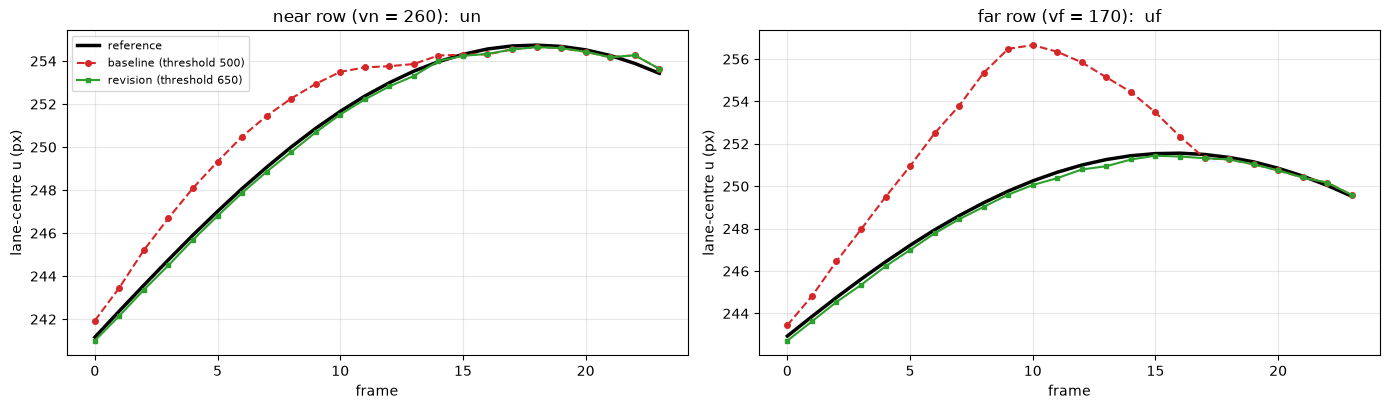

In [24]:
# Reference lane centres of the 'missing' sequence (read only now, for plotting / scoring)
with open(REFERENCE_CSV) as f:
    ref_rows = [r for r in csv.DictReader(f) if r["sequence"] == "missing"]
ref_rows.sort(key=lambda r: int(r["frame"]))
frames = [int(r["frame"]) for r in ref_rows]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for ax, key, ref_key, title in ((axes[0], "un", "near_center_x_px", "near row (vn = 260):  un"),
                                (axes[1], "uf", "far_center_x_px", "far row (vf = 170):  uf")):
    base = [r[key] for r in res_base if r["sequence"] == "missing"]
    rev = [r[key] for r in res_rev if r["sequence"] == "missing"]
    ax.plot(frames, [float(r[ref_key]) for r in ref_rows], "k-", linewidth=2.5, label="reference")
    ax.plot(frames, base, "o--", color="tab:red", markersize=4, label="baseline (threshold 500)")
    ax.plot(frames, rev, "s-", color="tab:green", markersize=3.5, label="revision (threshold 650)")
    ax.set_title(title)
    ax.set_xlabel("frame")
    ax.set_ylabel("lane-centre u (px)")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### e.3 · Two failure frames

Baseline (500, left) vs revision (650, right). Lime / magenta as in part (c); red = predicted centre, white × = reference (scoring only).

* **missing 009:** a plausible bright line (the seam) is wrong.
* **missing 013:** near row fine, far row wrong.

In [25]:
def show_seam_failure(sequence, frame_idx, thresholds=(WHITE_THRESHOLD_BASELINE, WHITE_THRESHOLD_REVISED)):
    """Compare the detector at several white thresholds on one frame.

    Shows the accepted white pixels, the fitted edges, the predicted centres at both rows and
    (for scoring only) the reference centres. Prints the numbers behind the picture.
    """

    image_rgb = load_frame(sequence, frame_idx)
    roi = image_rgb[ROI_START_V:, :, :]
    brightness = image_rgb.astype(np.int32).sum(axis=2)

    # Reference centres: read ONLY to score the finished predictions
    with open(REFERENCE_CSV) as f:
        ref = next(r for r in csv.DictReader(f)
                   if r["sequence"] == sequence and int(r["frame"]) == frame_idx)
    ref_centres = {V_NEAR: float(ref["near_center_x_px"]), V_FAR: float(ref["far_center_x_px"])}

    fig, axes = plt.subplots(1, len(thresholds), figsize=(7 * len(thresholds), 5))
    v_all = np.arange(ROI_START_V, image_rgb.shape[0])

    for ax, threshold in zip(axes, thresholds):
        left_points, right_points = collect_boundary_points(image_rgb, threshold)
        left_line = fit_boundary(left_points)
        right_line = fit_boundary(right_points)
        un, uf, conf_near, conf_far = predict_with_confidence(image_rgb, threshold)

        ax.imshow(roi)

        # Accepted white pixels: lime = clearly paint, magenta = accepted only because the threshold is low
        n_low = 0
        for pts in (left_points, right_points):
            if len(pts) == 0:
                continue
            v_pts = pts[:, 0].astype(int)
            u_pts = pts[:, 1].astype(int)
            is_paint = brightness[v_pts, u_pts] >= WHITE_THRESHOLD_REVISED
            n_low += int((~is_paint).sum())
            ax.plot(u_pts[is_paint], v_pts[is_paint] - ROI_START_V, ".", color="lime", markersize=2)
            ax.plot(u_pts[~is_paint], v_pts[~is_paint] - ROI_START_V, ".", color="magenta", markersize=2)

        # Straight-line fits through those pixels
        for line in (left_line, right_line):
            ax.plot([boundary_x(line, v) for v in v_all], v_all - ROI_START_V,
                    "--", color="yellow", linewidth=1.2)

        # Predicted vs reference centre on each row
        print(f"{sequence} {frame_idx:03d}, threshold {threshold}: "
              f"magenta pixels = {n_low}, left edge at far row = {boundary_x(left_line, V_FAR):.1f}")
        for name, v, u, conf in (("near", V_NEAR, un, conf_near), ("far", V_FAR, uf, conf_far)):
            error = abs(u - ref_centres[v])
            ax.plot(u, v - ROI_START_V, "o", color="red", markeredgecolor="white", markersize=9,
                    label=f"{name} predicted {u:.1f}  (ci {conf:.2f}, error {error:.1f} px)")
            ax.plot(ref_centres[v], v - ROI_START_V, "x", color="white", markersize=10, markeredgewidth=2,
                    label=f"{name} reference {ref_centres[v]:.1f}")
            ax.axhline(v - ROI_START_V, color="white", linestyle=":", linewidth=1)
            print(f"    {name}: predicted {u:.2f}  reference {ref_centres[v]:.2f}  error {error:.2f} px  confidence {conf:.2f}")

        ax.set_title(f"{sequence} {frame_idx:03d}  -  white threshold {threshold}")
        ax.set_xlabel("u (px)")
        ax.set_ylabel("v - 80 (px, crop indexing)")
        ax.legend(loc="lower center", fontsize=7.5, framealpha=0.8)

    plt.tight_layout()
    plt.show()

missing 009, threshold 500: magenta pixels = 78, left edge at far row = 180.4
    near: predicted 252.94  reference 250.87  error 2.07 px  confidence 1.00
    far: predicted 256.48  reference 249.77  error 6.71 px  confidence 0.75
missing 009, threshold 650: magenta pixels = 0, left edge at far row = 166.6
    near: predicted 250.68  reference 250.87  error 0.19 px  confidence 1.00
    far: predicted 249.60  reference 249.77  error 0.17 px  confidence 0.50


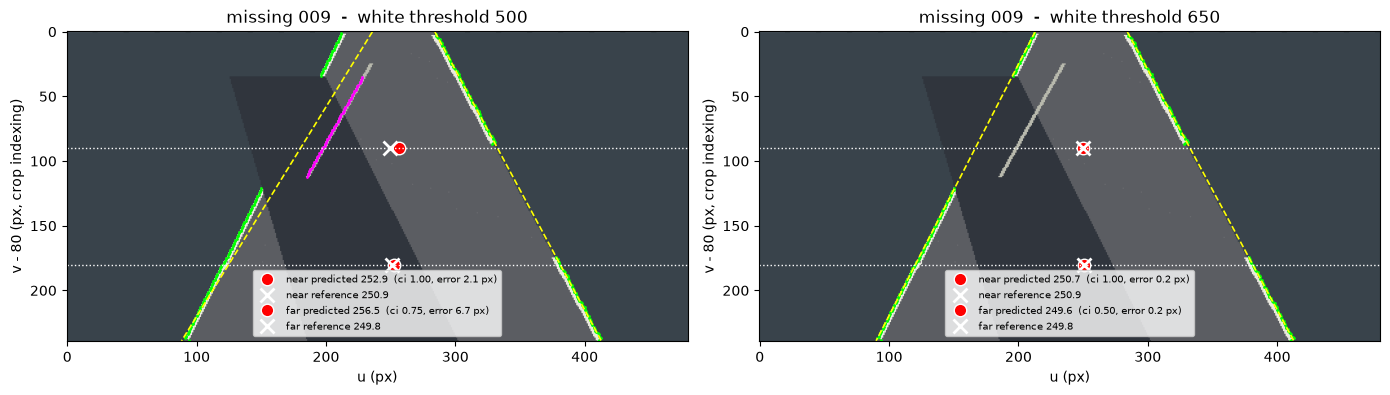

In [26]:
# Failure 1: a plausible bright line (the seam) is taken as the left lane edge
show_seam_failure("missing", 9)

missing 013, threshold 500: magenta pixels = 43, left edge at far row = 176.1
    near: predicted 253.86  reference 253.53  error 0.33 px  confidence 1.00
    far: predicted 255.14  reference 251.26  error 3.88 px  confidence 0.75
missing 013, threshold 650: magenta pixels = 0, left edge at far row = 167.8
    near: predicted 253.31  reference 253.53  error 0.22 px  confidence 1.00
    far: predicted 250.94  reference 251.26  error 0.32 px  confidence 0.75


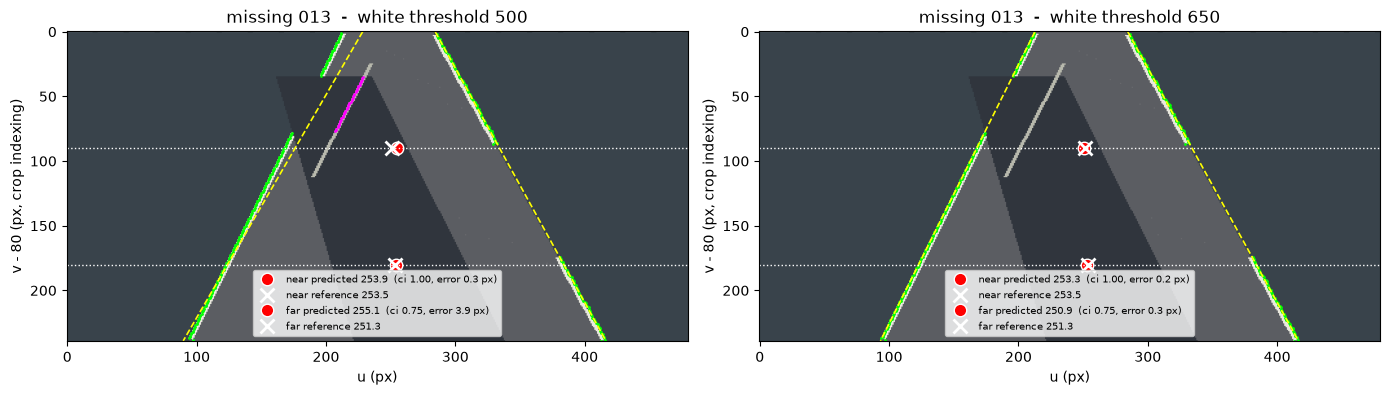

In [27]:
# Failure 2: near row plausible, far row wrong
show_seam_failure("missing", 13)

**missing 009.** The shadow hides the left paint around row 170, so the left-most pixel ≥ 500 is a seam pixel. The fit tilts: far centre 256.5 vs true 249.8 (error 6.7 px), near error 2.1 px. At 650 the seam is never accepted and the error drops to 0.2 px.

**missing 013.** Near error 0.3 px but far error 3.9 px. The estimated centres (253.9 → 255.1) drift right while the truth (253.5 → 251.3) drifts left, so a controller would infer the wrong heading. The confidence rule only partly flags it (far 0.75 vs near 1.0) and misses the cause, because the seam was directly detected: it measures missing evidence, not false evidence. At 650 the far error is 0.3 px.

### e.4 · The change and what it fixed

* **Change:** white threshold 500 → 650, justified by the brightness gap (seam ≈ 542, paint ≈ 686), plus a confidence value.
* **Fixed:** missing MAE 1.04 → 0.18 px (near) and 2.59 → 0.18 px (far); the 11 failing frames disappear. Clear is unchanged; no frame is unknown.
* **Cost:** shadow MAE rises slightly (≈ 0.17 → 0.24 px), likely because 650 rejects soft, dimmed paint pixels (500–650) that the baseline admits (untested). At 700 or more everything is unknown, so 650 relies on the paint staying near 686.
* **Limit:** the confidence does not detect a wrong line that is directly seen (frame 013). The data are synthetic.